# Fase A — Análisis Exploratorio (EDA)
Dataset: estadísticas de educación por municipio (MEN). Variable de interés: **DESERCIÓN**.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

CSV_PATH = "MEN_ESTADISTICAS_EN_EDUCACION_EN_PREESCOLAR,_BÁSICA_Y_MEDIA_POR_MUNICIPIO_20261014.csv"
zanahoria_2026_df_raw = pd.read_csv(CSV_PATH, sep=None, engine="python")
print(zanahoria_2026_df_raw.shape)

(15707, 41)


In [3]:

def ZANAHORIA_2026_a_numero(serie):
    """
    ZANAHORIA_2026
    Convierte una columna de texto con porcentajes (ej. '56.11%', '25,6%') a número.
    Quita el %, cambia la coma por punto y convierte a float. Lo no convertible queda NaN.
    """
    limpia = (serie.astype(str)
              .str.replace("%", "", regex=False)
              .str.replace(",", ".", regex=False)
              .str.strip())
    return pd.to_numeric(limpia, errors="coerce")

In [4]:

zanahoria_2026_df_eda = zanahoria_2026_df_raw.copy()

# Las filas NACIONAL son un total del país, no un municipio
es_nacional = zanahoria_2026_df_eda["MUNICIPIO"].str.upper().str.strip() == "NACIONAL"
zanahoria_2026_df_eda = zanahoria_2026_df_eda[~es_nacional].reset_index(drop=True)
print("Filas NACIONAL quitadas:", es_nacional.sum())

# ZANAHORIA_2026: columnas que no se convierten (texto e identificadores)
columnas_texto = ["MUNICIPIO", "DEPARTAMENTO", "ETC"]
columnas_id = ["AÑO", "CÓDIGO_MUNICIPIO", "CÓDIGO_DEPARTAMENTO", "CÓDIGO_ETC"]

# Todo lo demás se convierte a número
columnas_numericas = [c for c in zanahoria_2026_df_eda.columns if c not in columnas_texto + columnas_id]
for col in columnas_numericas:
    zanahoria_2026_df_eda[col] = ZANAHORIA_2026_a_numero(zanahoria_2026_df_eda[col])

print(zanahoria_2026_df_eda[["DESERCIÓN", "COBERTURA_NETA"]].describe())

Filas NACIONAL quitadas: 3
          DESERCIÓN  COBERTURA_NETA
count  15562.000000    15593.000000
mean       3.486068       85.243033
std        2.145781       16.839022
min        0.000000        0.000000
25%        1.950000       76.430000
50%        3.150000       86.050000
75%        4.640000       94.270000
max       27.900000      264.540000


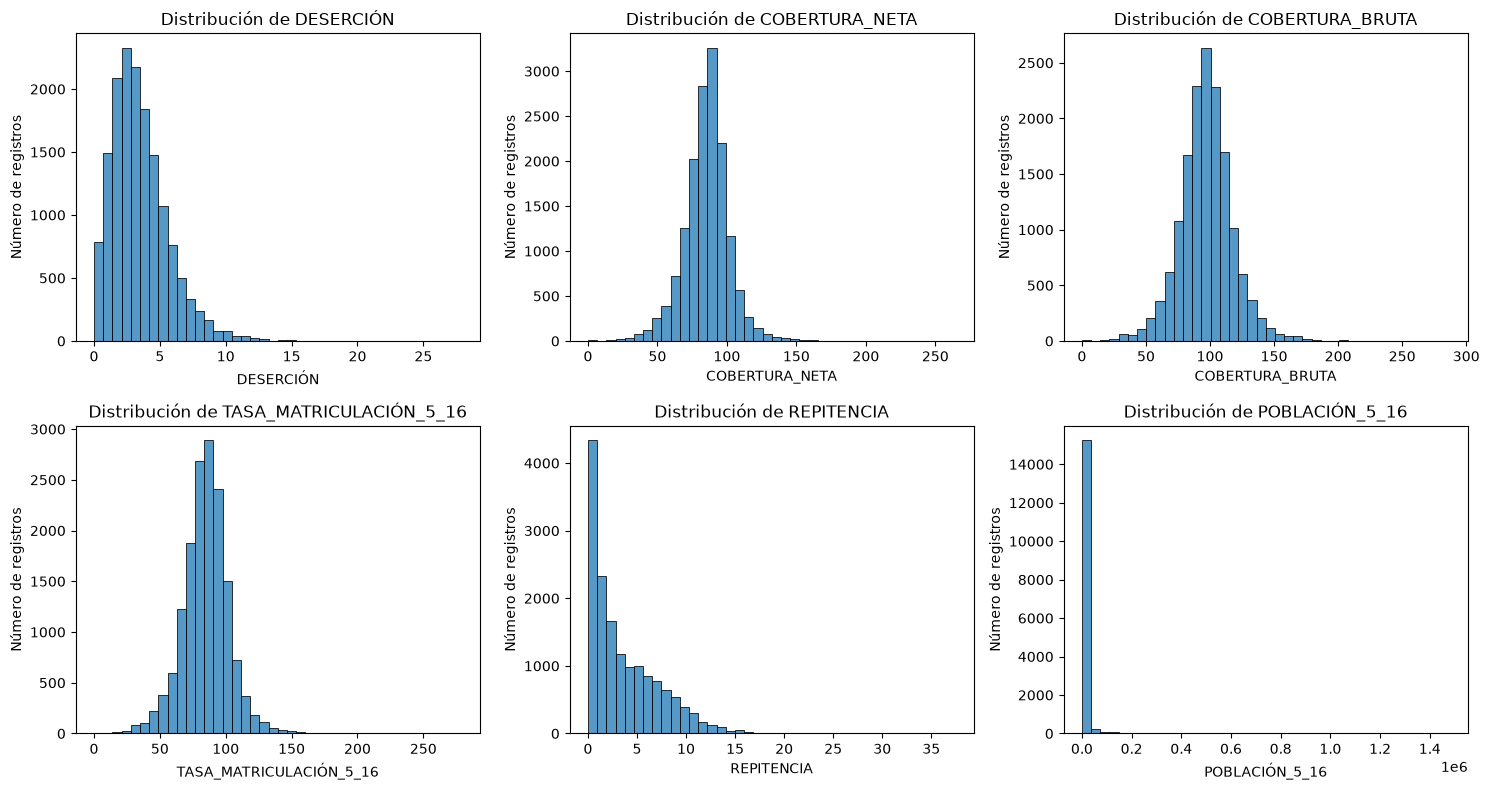

In [5]:

columnas_clave = ["DESERCIÓN", "COBERTURA_NETA", "COBERTURA_BRUTA",
                  "TASA_MATRICULACIÓN_5_16", "REPITENCIA", "POBLACIÓN_5_16"]

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(columnas_clave):
    ax = ejes.flat[i]
    sns.histplot(zanahoria_2026_df_eda[col].dropna(), bins=40, ax=ax)
    ax.set_title(f"Distribución de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Número de registros")

plt.tight_layout()
plt.savefig("zanahoria_2026_histogramas.png", dpi=120)
plt.show()

**Insight:** [completar después de ver el gráfico: forma de cada distribución, colas largas y qué significa para un municipio típico.]

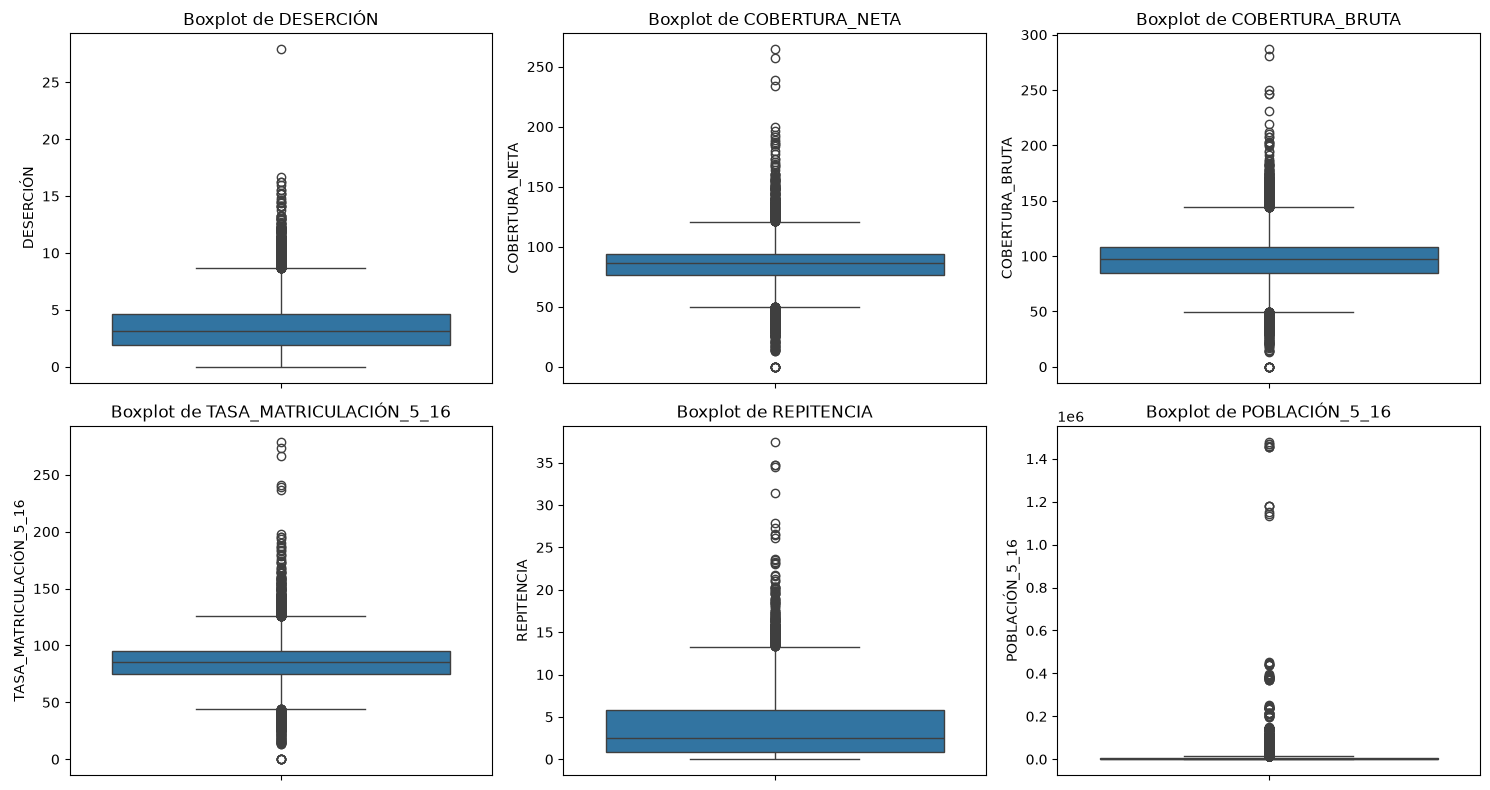

In [6]:
#Fase A, paso 5: boxplots para detectar outliers
fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(columnas_clave):
    ax = ejes.flat[i]
    sns.boxplot(y=zanahoria_2026_df_eda[col].dropna(), ax=ax)
    ax.set_title(f"Boxplot de {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.savefig("zanahoria_2026_boxplots.png", dpi=120)
plt.show()

**Insight:** [completar: qué variables tienen más atípicos y si son errores o casos reales, por ejemplo municipios muy pequeños.]

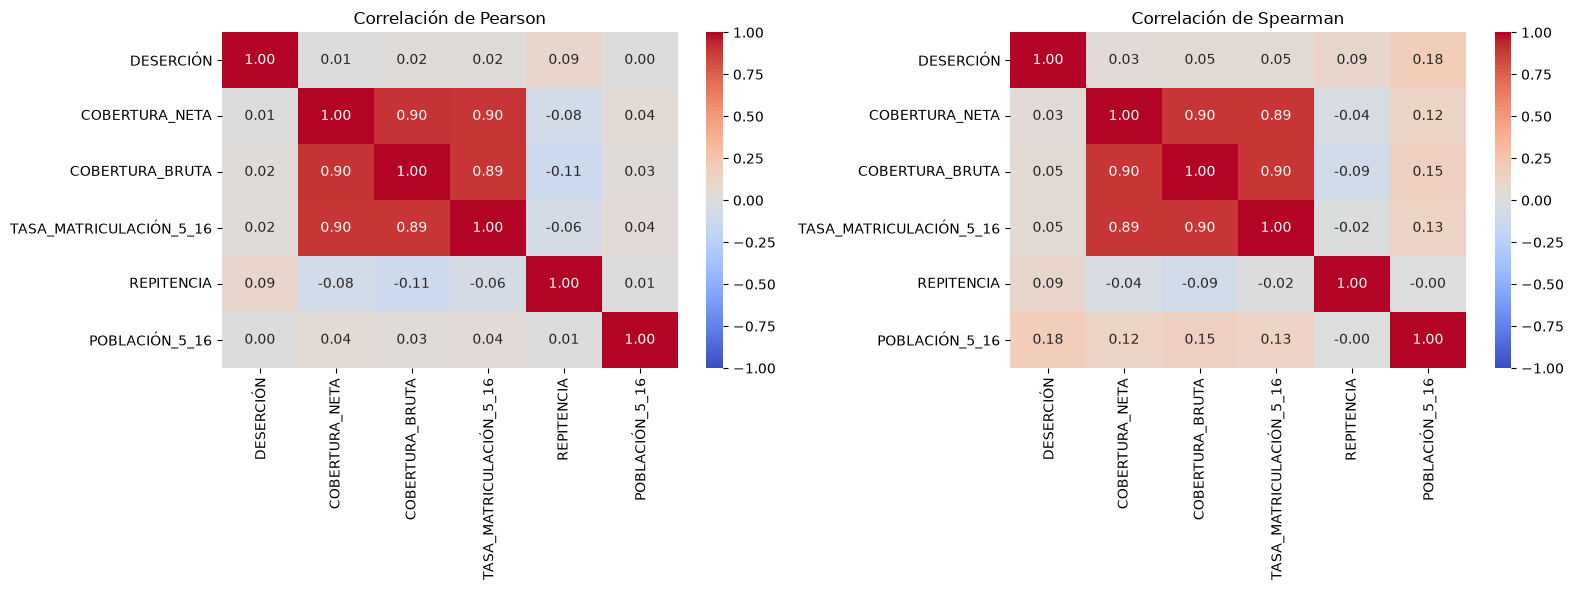

In [7]:
# - Fase A, paso 6: heatmaps de correlación (Pearson y Spearman)
zanahoria_2026_corr_pearson = zanahoria_2026_df_eda[columnas_clave].corr(method="pearson")
zanahoria_2026_corr_spearman = zanahoria_2026_df_eda[columnas_clave].corr(method="spearman")

fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(zanahoria_2026_corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ejes[0])
ejes[0].set_title("Correlación de Pearson")

# ZANAHORIA_2026: Spearman mide relaciones por orden, menos sensible a outliers
sns.heatmap(zanahoria_2026_corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ejes[1])
ejes[1].set_title("Correlación de Spearman")

plt.tight_layout()
plt.savefig("zanahoria_2026_heatmap_correlacion.png", dpi=120)
plt.show()

**Insight:** [completar: qué variables se relacionan más con la deserción y si Pearson y Spearman coinciden.]

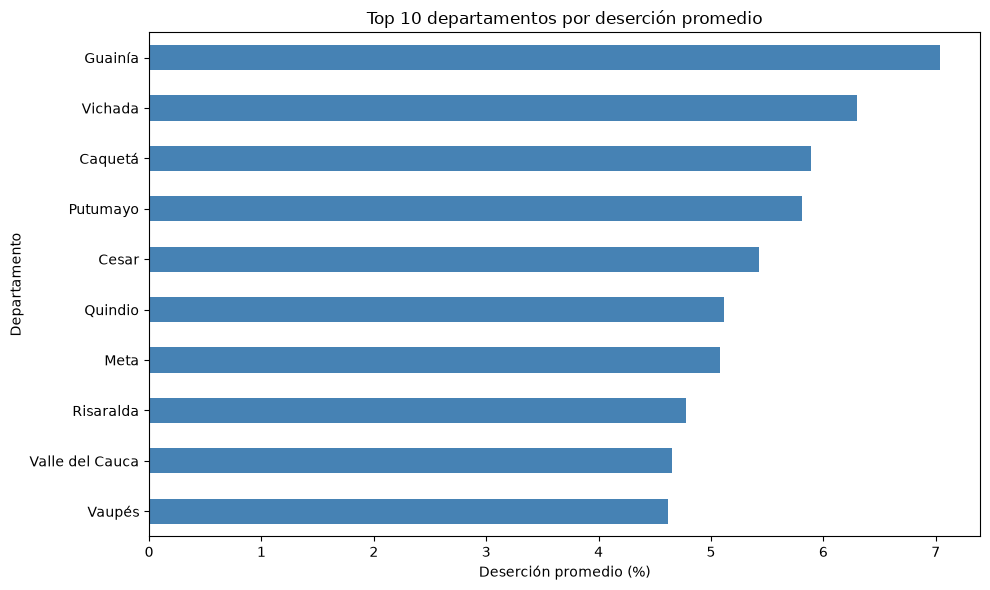

In [8]:
#- Fase A, paso 7: barras con los 10 departamentos de mayor deserción promedio
zanahoria_2026_desercion_depto = (zanahoria_2026_df_eda
                                  .groupby("DEPARTAMENTO")["DESERCIÓN"]
                                  .mean()
                                  .sort_values(ascending=False)
                                  .head(10))

fig, ax = plt.subplots(figsize=(10, 6))
zanahoria_2026_desercion_depto.plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Top 10 departamentos por deserción promedio")
ax.set_xlabel("Deserción promedio (%)")
ax.set_ylabel("Departamento")
ax.invert_yaxis()  # el mayor queda arriba
plt.tight_layout()
plt.savefig("zanahoria_2026_barras_departamentos.png", dpi=120)
plt.show()

**Insight:** [completar: qué departamentos destacan y qué tan grande es la diferencia frente al promedio.]

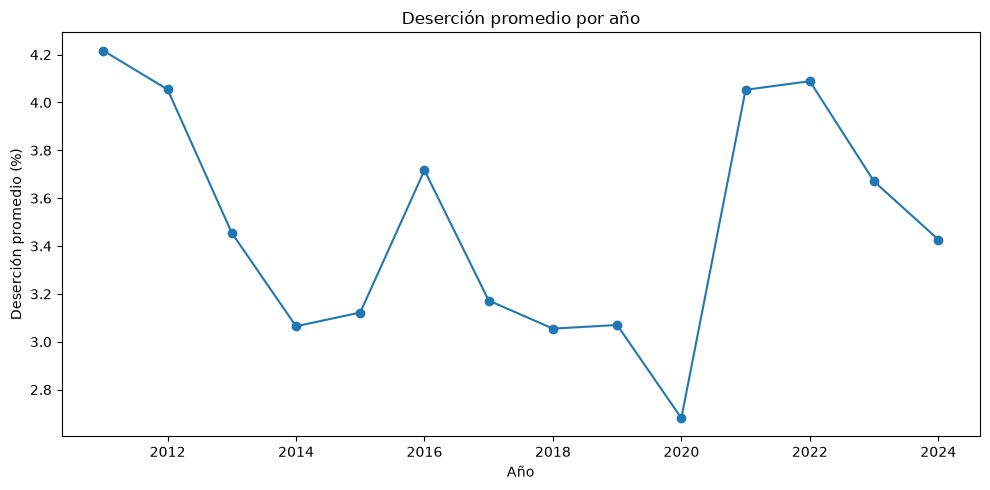

In [9]:
# - Fase A, paso 8: línea con la deserción promedio por año
zanahoria_2026_desercion_anio = zanahoria_2026_df_eda.groupby("AÑO")["DESERCIÓN"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
zanahoria_2026_desercion_anio.plot(kind="line", marker="o", ax=ax)
ax.set_title("Deserción promedio por año")
ax.set_xlabel("Año")
ax.set_ylabel("Deserción promedio (%)")
plt.tight_layout()
plt.savefig("zanahoria_2026_linea_anios.png", dpi=120)
plt.show()

**Insight:** [completar: si la deserción sube, baja o se mantiene con los años y qué podría explicarlo.]

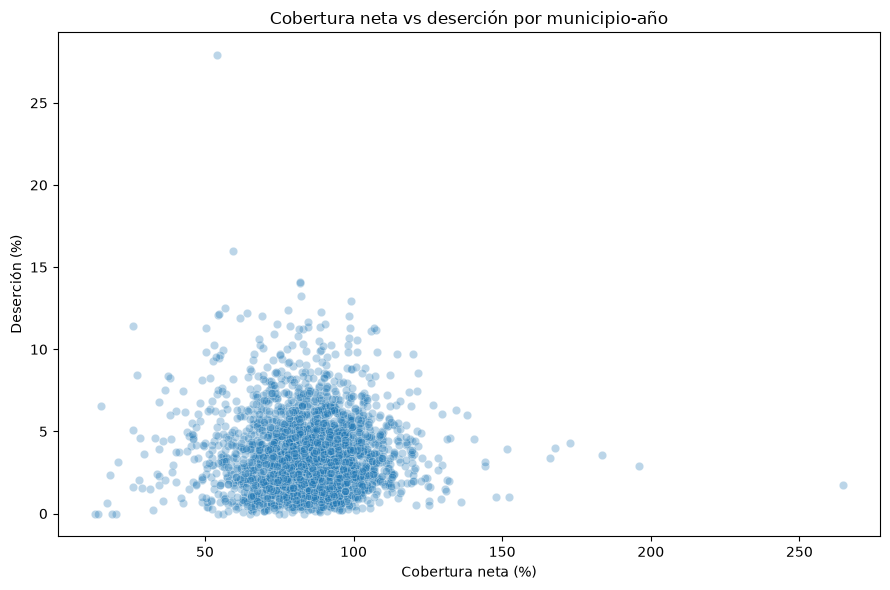

In [10]:
# - Fase A, paso 9: dispersión cobertura neta vs deserción (muestra de 3000 filas)
zanahoria_2026_muestra = (zanahoria_2026_df_eda
                          .dropna(subset=["COBERTURA_NETA", "DESERCIÓN"])
                          .sample(3000, random_state=42))

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=zanahoria_2026_muestra, x="COBERTURA_NETA", y="DESERCIÓN", alpha=0.3, ax=ax)
ax.set_title("Cobertura neta vs deserción por municipio-año")
ax.set_xlabel("Cobertura neta (%)")
ax.set_ylabel("Deserción (%)")
plt.tight_layout()
plt.savefig("zanahoria_2026_dispersion_cobertura_desercion.png", dpi=120)
plt.show()

**Insight:** [completar: si más cobertura se asocia con menos deserción y qué tan fuerte es la relación.]